# DSS Desa Wisata Indonesia — FINAL TERINTEGRASI (1.336 identitas)
### Tahap A + Tahap B + kalibrasi probabilitas + TF-IDF + Permutation SHAP

**Ruang lingkup:** prototipe *decision support system* berbasis benchmark (987 di luar benchmark, 315 Maju, 34 Mandiri). **Status JADESTA belum terverifikasi.** Di luar benchmark **bukan** label resmi Rintisan/Berkembang. Skor adalah *benchmark-alignment score*, **bukan** probabilitas kenaikan status resmi, ukuran kualitas kausal, ataupun sertifikasi kesiapan.

**Model terkunci dari eksperimen sebelumnya:** Tahap A = Logistic Regression + TF-IDF saja; Tahap B = Random Forest dengan fitur terstruktur + TF-IDF. Dua model dibandingkan sebelumnya terhadap Calibrated Linear SVM dan algoritma lain. Pemilihan **tidak** menggunakan ulang holdout untuk mengoptimasi model.

**Audit riwayat:** ZIP robustness Tahap A yang diunggah memiliki `FAST_MODE=true`, outer CV 3×1, threshold A **0.44** pada keluaran **sebelum** kalibrasi. Angka tersebut menjadi referensi, **tidak disalin langsung** setelah sigmoid calibration. Threshold baru diperoleh dari OOF training saja.

**Evaluasi sah untuk pengembangan:** CV terpisah + nested hierarchical OOF di dalam training, tanpa melibatkan holdout lama. Hasil holdout 268 desa, jika dinyalakan, hanyalah **diagnostik dataset yang sudah pernah dilihat**, tidak boleh diklaim sebagai evaluasi independen baru.

**Cara menjalankan:** buka di Colab; unggah ketiga CSV; jalankan `Runtime → Run all`. Untuk pengujian cepat ubah `FAST_MODE=True` di sel konfigurasi. Output CSV/PNG/JSON/joblib/ZIP diunduh pada sel terakhir.

## 0. Pustaka, konfigurasi, dan kendali eksperimen

In [ ]:
import os, sys, re, json, zipfile, warnings, random, hashlib, platform, time
from pathlib import Path
from urllib.parse import urlparse
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from sklearn import __version__ as SKLEARN_VERSION
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (accuracy_score,balanced_accuracy_score,precision_score,recall_score,f1_score,
    average_precision_score,roc_auc_score,brier_score_loss,log_loss,confusion_matrix,
    classification_report,ConfusionMatrixDisplay)
from scipy.stats import beta
import joblib

SEED=42
random.seed(SEED); np.random.seed(SEED)
FAST_MODE=False       # Ubah True hanya untuk UJI KODE, bukan hasil publikasi
RUN_BENCHMARK=True    # tiga algoritma untuk A dan B, CV training saja; diagnostik
RUN_NESTED_HIERARCHY=True  # nested outer/inner CV 3 kelas pada training saja
RUN_REUSED_HOLDOUT_DIAGNOSTIC=True  # hasilnya TIDAK independen karena holdout lama sudah dilihat
RUN_SHAP=True
SAVE_MODELS=True
CV_FOLDS=2 if FAST_MODE else 3
OUTER_FOLDS=2 if FAST_MODE else 3
RF_TREES=35 if FAST_MODE else 160
BG_COUNTS=(3,2,2) if FAST_MODE else (8,6,4)
EXP_COUNTS=(3,2,1) if FAST_MODE else (8,6,4)
SHAP_PERMUTATIONS=1 if FAST_MODE else 2
LABEL_NAMES={0:'Di Luar Benchmark',1:'Maju',2:'Mandiri'}
FILES={0:'DESA_DI_LUAR_BENCHMARK_987.csv',1:'DESA_MAJU_315.csv',2:'DESA_MANDIRI_34.csv'}
OUT_DIR=Path('/content/HASIL_DSS_FINAL_AB' if Path('/content').exists() else '/mnt/data/HASIL_DSS_FINAL_AB')
OUT_DIR.mkdir(parents=True,exist_ok=True)
REF_A_MODEL='Logistic Regression'; REF_A_FEATURE='tfidf_only'; REF_A_THRESHOLD_UNCALIBRATED=0.44
REF_B_MODEL='Random Forest'; CAL_METHOD='sigmoid'
EXPECTED_TRAIN_SHA='5aa6a86e2c0aabe3210a076fdfde29d11a3d24b1985bc73c40daef5f0c3d8c53'
EXPECTED_TEST_SHA='bea3c189273b5a72354360a3810b90b17dcbdca102a7f2b2acad68f82a140325'
print('MODE:', 'FAST / tidak untuk publikasi' if FAST_MODE else 'FULL', '| sklearn:',SKLEARN_VERSION,'| lokasi output:',OUT_DIR)

MODE: FULL | sklearn: 1.6.1 | lokasi output: /content/HASIL_DSS_FINAL_AB


## 1. Muat dan audit tiga CSV (label sementara, tidak diubah diam-diam)

In [ ]:
missing_files = [name for name in FILES.values() if not Path(name).exists()]
if missing_files:
    try:
        from google.colab import files as colab_files
        print('Silakan unggah semua CSV berikut:', missing_files)
        colab_files.upload()
    except ImportError as exc:
        raise FileNotFoundError('Salin file berikut ke folder kerja: ' + ', '.join(missing_files)) from exc

frames = []
for label, filename in FILES.items():
    if not Path(filename).exists():
        raise FileNotFoundError('CSV tidak tersedia: ' + filename)
    part = pd.read_csv(filename, dtype=str, keep_default_na=False, encoding='utf-8-sig')
    part['label_3kelas'] = label
    part['status_benchmark'] = LABEL_NAMES[label]
    part['file_sumber_label'] = filename
    frames.append(part)
    print(filename, '->', len(part), 'baris')

df_raw = pd.concat(frames, ignore_index=True)
assert df_raw.shape[0] == 1336, f'Jumlah data berubah: {len(df_raw)}. Audit sumber sebelum melanjutkan.'
assert df_raw['label_3kelas'].value_counts().to_dict() == {0: 987, 1: 315, 2: 34}
required_columns = ['Desa Wisata','Kabupaten','Deskripsi','Fasilitas','Atraksi','homestay',
                    'pakert wisata','sovenir','HP','IG','FB','Email','Website','Twitter','matching_key']
missing_cols = sorted(set(required_columns) - set(df_raw.columns))
assert not missing_cols, f'Kolom hilang: {missing_cols}'
assert (df_raw['matching_key'].astype(str).str.strip() != '').all(), 'Ada matching_key kosong'
assert not df_raw['matching_key'].duplicated().any(), 'Identitas desa terduplikasi. Periksa sumber!'
assert (df_raw['status_terverifikasi_JADESTA'].str.upper() == 'BELUM').all(), 'Status verifikasi berubah; periksa ulang metodologi.'

summary = df_raw.groupby(['label_3kelas','status_benchmark']).size().reset_index(name='jumlah')
summary['persentase'] = (summary['jumlah'] / len(df_raw) * 100).round(2)
display(summary)
summary.to_csv(OUT_DIR/'01_distribusi_label.csv', index=False, encoding='utf-8-sig')
print('Total identitas unik:', df_raw['matching_key'].nunique())
print('PENTING: Seluruh label adalah benchmark sementara, bukan verifikasi JADESTA.')

Silakan unggah semua CSV berikut: ['DESA_DI_LUAR_BENCHMARK_987.csv', 'DESA_MAJU_315.csv', 'DESA_MANDIRI_34.csv']


Saving DESA_DI_LUAR_BENCHMARK_987.csv to DESA_DI_LUAR_BENCHMARK_987.csv
Saving DESA_MAJU_315.csv to DESA_MAJU_315.csv
Saving DESA_MANDIRI_34.csv to DESA_MANDIRI_34.csv
DESA_DI_LUAR_BENCHMARK_987.csv -> 987 baris
DESA_MAJU_315.csv -> 315 baris
DESA_MANDIRI_34.csv -> 34 baris


,label_3kelas,status_benchmark,jumlah,persentase
0,0,Di Luar Benchmark,987,73.88
1,1,Maju,315,23.58
2,2,Mandiri,34,2.54


Total identitas unik: 1336
PENTING: Seluruh label adalah benchmark sementara, bukan verifikasi JADESTA.


## 2. Rekonstruksi fitur dan teks yang identik dengan eksperimen Tahap A robustness

In [ ]:
EMPTY_VALUES = {'', '-', '--', '---', 'nan', 'none', 'null', 'n/a', 'na', 'tidak ada', 'belum ada', 'tdk ada'}
PSEUDO = {
    'Fasilitas': {'fasilitas', 'belum ada fasilitas untuk ditampilkan', 'belum tersedia'},
    'Atraksi': {'atraksi wisata', 'atraksi', 'belum ada atraksi untuk ditampilkan'},
    'homestay': {'kamar homestay', 'homestay', 'belum ada homestay untuk ditampilkan'},
    'pakert wisata': {'paket wisata', 'belum ada paket wisata untuk ditampilkan'},
    'sovenir': {'suvenir', 'souvenir', 'belum ada suvenir untuk ditampilkan'},
}

def clean_text(value):
    if pd.isna(value):
        return ''
    text = str(value).strip()
    if text.lower() in EMPTY_VALUES:
        return ''
    # Hapus ekspresi penghargaan/ranking yang berpotensi membocorkan label
    text = re.sub(r'\b\d+\s*besar\s*adwi\s*(?:20\d{2})?\b', ' ', text, flags=re.I)
    text = re.sub(r'\badwi\s*(?:20\d{2})?\b', ' ', text, flags=re.I)
    text = re.sub(r'\b(?:status|klasifikasi|kategori)\s+(?:desa\s+wisata\s+)?(?:mandiri|maju|rintisan|berkembang)\b', ' ', text, flags=re.I)
    return re.sub(r'\s+', ' ', text).strip()

def count_documented_items(value, column):
    text = clean_text(value)
    if not text or 'belum ada' in text.lower() or 'belum tersedia' in text.lower():
        return 0
    # Harga dalam format Rp 150,000 tidak boleh dihitung sebagai 2 entri
    text = re.sub(r'(?<=\d),(?=\d{3}(?:\D|$))', '', text)
    parts = re.split(r'[,;\n\r|]+', text)
    items = []
    for item in parts:
        item = item.strip(' .-_')
        if not item or item.lower() in PSEUDO[column]:
            continue
        for heading in PSEUDO[column]:
            if item.lower().startswith(heading + ' ') and len(item) > len(heading) + 2:
                item = item[len(heading):].strip()
        if item and item.lower() not in PSEUDO[column]:
            items.append(item)
    return len(items)

def valid_channel(value, channel):
    s = clean_text(value)
    if not s:
        return 0
    if channel == 'HP':
        return int(len(re.sub(r'\D', '', s)) >= 8)
    if channel == 'Email':
        return int(bool(re.search(r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Za-z]{2,}\b', s)))
    url = s if re.match(r'^https?://', s, flags=re.I) else 'https://' + s
    parsed = urlparse(url)
    host = parsed.netloc.lower().removeprefix('www.')
    slug = parsed.path.strip('/').lower()
    if channel == 'IG':
        return int(host in ('instagram.com','instagr.am') and slug not in ('','p','reel','stories','explore','jadestaofficial'))
    if channel == 'FB':
        return int(host in ('facebook.com','m.facebook.com','fb.com') and slug not in ('','jadestaofficial'))
    if channel == 'Twitter':
        return int(host in ('twitter.com','x.com') and slug not in ('','jadestaofficial','home','search'))
    if channel == 'Website':
        banned = ('facebook.com','instagram.com','twitter.com','x.com','wa.me','whatsapp.com',
                  'wa.link','linktr.ee','jadesta.kemenpar.go.id','jadesta.kemenparekraf.go.id')
        return int(bool(host and '.' in host and not any(host == d or host.endswith('.'+d) for d in banned)))
    return 0

NUM_COLS = ['description_length','num_facilities','num_attractions','num_homestay',
            'num_tour_packages','num_souvenirs','has_phone','has_instagram',
            'has_facebook','has_email','has_website','has_twitter']
TEXT_COL = 'combined_text_model'
TEXT_SOURCE_COLS = ['Deskripsi','Fasilitas','Atraksi','homestay','pakert wisata','sovenir']

df = df_raw.copy()
for col in required_columns:
    df[col] = df[col].fillna('').astype(str)
for col in TEXT_SOURCE_COLS:
    df['clean_' + col] = df[col].map(clean_text)

df['description_length'] = df['clean_Deskripsi'].map(lambda x: len(re.findall(r'\b\w+\b', x)))
for col, feature in [('Fasilitas','num_facilities'),('Atraksi','num_attractions'),
                     ('homestay','num_homestay'),('pakert wisata','num_tour_packages'),('sovenir','num_souvenirs')]:
    df[feature] = df[col].map(lambda x: count_documented_items(x, col))
for col, feature in [('HP','has_phone'),('IG','has_instagram'),('FB','has_facebook'),
                     ('Email','has_email'),('Website','has_website'),('Twitter','has_twitter')]:
    df[feature] = df[col].map(lambda x: valid_channel(x, col))

df[TEXT_COL] = df[['clean_' + col for col in TEXT_SOURCE_COLS]].agg(' '.join,axis=1).str.replace(r'\s+',' ',regex=True).str.strip()
for col in NUM_COLS:
    df[col] = pd.to_numeric(df[col], errors='raise').astype(float)
df['digital_presence_score'] = df[['has_instagram','has_facebook','has_email','has_website','has_twitter']].sum(axis=1)
df['product_readiness_score'] = df[['num_attractions','num_tour_packages','num_souvenirs']].sum(axis=1)
df['infrastructure_readiness_score'] = df[['num_facilities','num_homestay']].sum(axis=1)
assert df[NUM_COLS+[TEXT_COL]].notna().all().all()
assert (df[NUM_COLS].to_numpy() >= 0).all()

X_ALL = df[NUM_COLS+[TEXT_COL]].copy()
y_all = df['label_3kelas'].astype(int)
print('Matriks mentah prediktor:',X_ALL.shape,'| 12 numerik + 1 blok teks')
display(df.groupby('status_benchmark')[NUM_COLS].agg(['mean','median']).round(2).iloc[:,:12])
df[['matching_key','label_3kelas']+NUM_COLS+['digital_presence_score','product_readiness_score','infrastructure_readiness_score']].to_csv(
    OUT_DIR/'02_fitur_terstruktur_audit.csv',index=False,encoding='utf-8-sig')

Matriks mentah prediktor: (1336, 13) | 12 numerik + 1 blok teks


description_length        num_facilities         \
                                mean median           mean median   
status_benchmark                                                    
Di Luar Benchmark             186.45   89.0           6.57    7.0   
Maju                          215.37  135.0           8.82   10.0   
Mandiri                        65.68   51.0           9.71   10.0   

                  num_attractions        num_homestay         \
                             mean median         mean median   
status_benchmark                                               
Di Luar Benchmark            4.25    2.0         1.51    0.0   
Maju                         6.91    5.0         3.38    2.0   
Mandiri                      6.24    4.0         0.65    0.0   

                  num_tour_packages        num_souvenirs         
                               mean median          mean median  
status_benchmark                                                 
Di Luar Benchmark              2.21    1.0          1.76    0.0  
Maju                           3.77    2.0          2.78    2.0  
Mandiri                        3.71    1.0          1.97    0.5

## 3. Split 80:20 yang dikunci — periksa sidik jari identitas train/test

In [ ]:
train_idx, test_idx = train_test_split(df.index.to_numpy(), test_size=0.20, stratify=y_all, random_state=SEED)
train_idx, test_idx = np.sort(train_idx), np.sort(test_idx)
assert len(set(train_idx) & set(test_idx)) == 0
train = df.loc[train_idx].copy()
test = df.loc[test_idx].copy()
X_train = train[NUM_COLS + [TEXT_COL]].copy()
X_test = test[NUM_COLS + [TEXT_COL]].copy()
y_A_train = (train['label_3kelas'] >= 1).astype(int)
y_A_test = (test['label_3kelas'] >= 1).astype(int)
train_B = train[train['label_3kelas'].isin([1,2])].copy()
test_B = test[test['label_3kelas'].isin([1,2])].copy()
X_B_train = train_B[NUM_COLS + [TEXT_COL]].copy()
X_B_test = test_B[NUM_COLS + [TEXT_COL]].copy()
y_B_train = (train_B['label_3kelas'] == 2).astype(int)
y_B_test = (test_B['label_3kelas'] == 2).astype(int)

split_table = pd.concat([
    train['label_3kelas'].value_counts().sort_index().rename('train_80'),
    test['label_3kelas'].value_counts().sort_index().rename('test_20')], axis=1).fillna(0).astype(int)
split_table['total'] = split_table.sum(axis=1)
split_table['kelas'] = split_table.index.map(LABEL_NAMES)
display(split_table)
split_table.to_csv(OUT_DIR/'03_split_train_test.csv',encoding='utf-8-sig')
train[['matching_key','Desa Wisata','Kabupaten','label_3kelas']].to_csv(OUT_DIR/'03_train_ids.csv',index=False,encoding='utf-8-sig')
test[['matching_key','Desa Wisata','Kabupaten','label_3kelas']].to_csv(OUT_DIR/'03_test_ids.csv',index=False,encoding='utf-8-sig')

,train_80,test_20,total,kelas
label_3kelas,,,,
0,789,198,987,Di Luar Benchmark
1,252,63,315,Maju
2,27,7,34,Mandiri


In [ ]:
def split_signature(keys):
    return hashlib.sha256('\n'.join(sorted(keys.astype(str))).encode('utf-8')).hexdigest()
actual_train_sha=split_signature(train['matching_key'])
actual_test_sha=split_signature(test['matching_key'])
assert actual_train_sha==EXPECTED_TRAIN_SHA and actual_test_sha==EXPECTED_TEST_SHA, (
    'Split tidak cocok dengan hasil robustness lama! Periksa dataset/urutan input sebelum melanjutkan.')
assert set(train['matching_key']).isdisjoint(test['matching_key'])
print('PASS: split identik dengan eksperimen robustness.', '\ntrain_sha:',actual_train_sha,'\ntest_sha :',actual_test_sha)
print('HOLDOUT LAMA SUDAH DIPERIKSA pada eksperimen terdahulu; bukan test baru independen.')

PASS: split identik dengan eksperimen robustness. 
train_sha: 5aa6a86e2c0aabe3210a076fdfde29d11a3d24b1985bc73c40daef5f0c3d8c53 
test_sha : bea3c189273b5a72354360a3810b90b17dcbdca102a7f2b2acad68f82a140325
HOLDOUT LAMA SUDAH DIPERIKSA pada eksperimen terdahulu; bukan test baru independen.


## 4. Pembuatan model A/B dan pembanding

- **A (terkunci):** Logistic Regression + TF-IDF unigram/bigram 3.000 fitur, `class_weight=balanced`.
- **B (terkunci):** Random Forest (`class_weight=balanced_subsample`) pada 12 fitur terstruktur + TF-IDF.
- Logistic Regression, Calibrated Linear SVM, dan Random Forest tetap tersedia untuk perbandingan CV, **tanpa mengubah model terpilih** berdasarkan hasil tersebut.
- Kalibrasi sigmoid dilakukan **di dalam fold pelatihan** (`CalibratedClassifierCV`).

Section 4.1. TF-IDF Text Representation Audit

Tambahkan blok kode audit di sini

Menghasilkan data empiris untuk Table 7

In [ ]:
# ============================================================
# ADDITIONAL BLOCK
# TF-IDF TEXT REPRESENTATION AUDIT
# Training-only analysis for manuscript Section 3.5
# ============================================================

import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer
from IPython.display import display

TFIDF_PARAMS = {
    'ngram_range': (1, 2),
    'min_df': 2,
    'max_df': 0.95,
    'max_features': 3000,
    'sublinear_tf': True,
    'strip_accents': None
}

audit_results = []
top_terms_results = []

# Safely define Xa and Xb locally in case cell 8ceed521 has not been executed yet
XCOLS = NUM_COLS + [TEXT_COL]
Xa_local = train[XCOLS].reset_index(drop=True)
trB_local = train[train['label_3kelas'].isin([1, 2])].copy()
Xb_local = trB_local[XCOLS].reset_index(drop=True)

stage_data = {
    'Stage A': Xa_local,
    'Stage B': Xb_local
}

for stage_name, X_stage in stage_data.items():

    # Training-only TF-IDF audit
    texts = X_stage[TEXT_COL].fillna('').astype(str)

    vectorizer = TfidfVectorizer(**TFIDF_PARAMS)

    X_tfidf = vectorizer.fit_transform(texts)

    terms = vectorizer.get_feature_names_out()

    n_docs, n_features = X_tfidf.shape
    non_zero = X_tfidf.nnz

    density = non_zero / (n_docs * n_features)
    sparsity = 1 - density

    n_unigrams = sum(' ' not in term for term in terms)
    n_bigrams = sum(' ' in term for term in terms)

    structured_features = (
        0 if stage_name == 'Stage A' else len(NUM_COLS)
    )

    audit_results.append({
        'Stage': stage_name,
        'Training documents': n_docs,
        'Actual vocabulary size': n_features,
        'Unigram features': n_unigrams,
        'Bigram features': n_bigrams,
        'Structured features': structured_features,
        'Total feature dimensionality':
            n_features + structured_features,
        'Non-zero elements': non_zero,
        'Density (%)': density * 100,
        'Sparsity (%)': sparsity * 100,
        'Empty input documents':
            int(texts.str.strip().eq('').sum()),
        'Zero TF-IDF vectors':
            int((X_tfidf.getnnz(axis=1) == 0).sum())
    })

    # Average TF-IDF weights
    mean_weights = np.asarray(
        X_tfidf.mean(axis=0)
    ).ravel()

    top_terms = pd.DataFrame({
        'Term': terms,
        'Mean TF-IDF weight': mean_weights
    }).sort_values(
        'Mean TF-IDF weight',
        ascending=False
    ).head(20)

    top_terms.insert(0, 'Stage', stage_name)

    top_terms_results.append(top_terms)

# Summary table
df_tfidf_audit = pd.DataFrame(audit_results)

print("=" * 75)
print("TF-IDF TEXT REPRESENTATION AUDIT")
print("=" * 75)

display(df_tfidf_audit.round(4))

# Top terms
df_top_tfidf = pd.concat(
    top_terms_results,
    ignore_index=True
)

print("\nTOP 20 TERMS FOR EACH STAGE")
display(df_top_tfidf.round(6))

# Export results
df_tfidf_audit.to_csv(
    OUT_DIR / 'TFIDF_representation_audit.csv',
    index=False
)

df_top_tfidf.to_csv(
    OUT_DIR / 'TFIDF_top20_terms.csv',
    index=False
)

NameError: name 'NUM_COLS' is not defined

In [ ]:
NUM_CORE=NUM_COLS[:6]

def features_pipeline(include_num=True,include_text=True):
    tr=[]
    if include_num: tr.append(('num',StandardScaler(),NUM_COLS))
    if include_text: tr.append(('text',TfidfVectorizer(
        ngram_range=(1,2), min_df=2, max_df=0.95, max_features=3000,
        sublinear_tf=True, strip_accents=None),TEXT_COL))
    return ColumnTransformer(tr,remainder='drop',sparse_threshold=0.30)

def base_estimator(stage, model_name=None):
    if stage=='A':
        model_name=model_name or REF_A_MODEL
        num=False  # HASIL ABLASI: Tahap A terpilih adalah TF-IDF saja
    else:
        model_name=model_name or REF_B_MODEL
        num=True
    feat=features_pipeline(include_num=num,include_text=True)
    if model_name=='Logistic Regression':
        model=LogisticRegression(solver='liblinear',class_weight='balanced',max_iter=2500,random_state=SEED)
    elif model_name=='Calibrated Linear SVM':
        svc_base=Pipeline([('features',feat),('model',LinearSVC(dual='auto',class_weight='balanced',max_iter=6000,random_state=SEED))])
        # SVM harus terkalibrasi untuk memberi probabilitas; jangan kalibrasi dua kali
        return CalibratedClassifierCV(estimator=svc_base,method='sigmoid',cv=3)
    elif model_name=='Random Forest':
        model=RandomForestClassifier(n_estimators=RF_TREES,min_samples_leaf=2,
            class_weight='balanced_subsample',n_jobs=-1,random_state=SEED)
    else: raise ValueError(model_name)
    return Pipeline([('features',feat),('model',model)])

def calibrated_model(stage):
    return CalibratedClassifierCV(estimator=base_estimator(stage),method=CAL_METHOD,cv=CV_FOLDS)

XCOLS=NUM_COLS+[TEXT_COL]
Xa=train[XCOLS].reset_index(drop=True)
ya=(train['label_3kelas'].to_numpy()>=1).astype(int)
trB=train[train['label_3kelas'].isin([1,2])].copy()
Xb=trB[XCOLS].reset_index(drop=True)
yb=(trB['label_3kelas'].to_numpy()==2).astype(int)
assert len(Xa)==1068 and len(Xb)==279 and (yb==1).sum()==27
print('Tahap A:',Xa.shape, 'positif:',ya.sum(),'| Tahap B:',Xb.shape,'Mandiri:',yb.sum())

Tahap A: (1068, 13) positif: 279 | Tahap B: (279, 13) Mandiri: 27


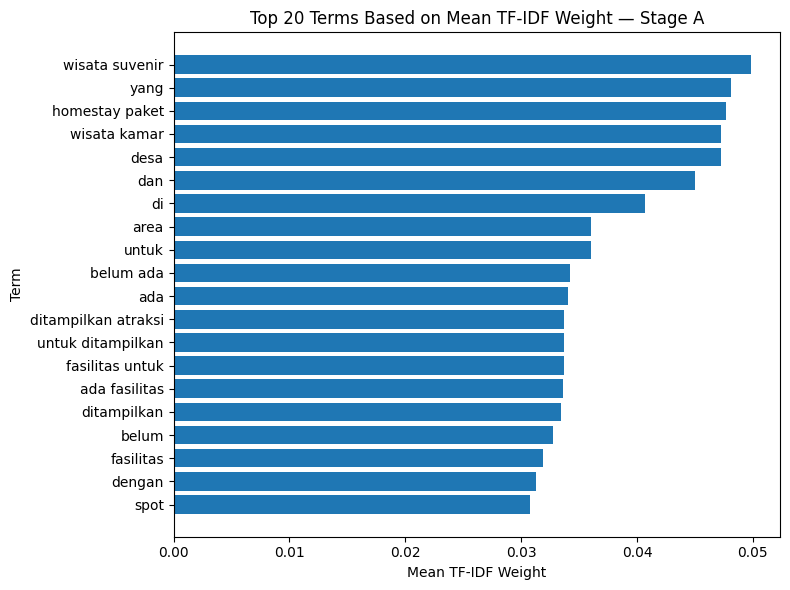

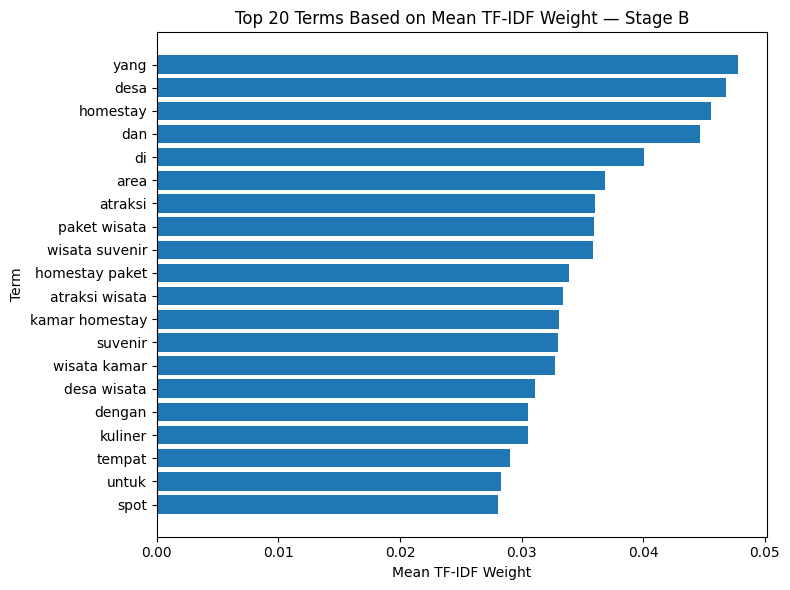

In [ ]:
# ============================================================
# TF-IDF TOP 20 TERMS VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

for stage_name in ['Stage A', 'Stage B']:

    plot_data = df_top_tfidf[
        df_top_tfidf['Stage'] == stage_name
    ].sort_values('Mean TF-IDF weight')

    plt.figure(figsize=(8, 6))

    plt.barh(
        plot_data['Term'],
        plot_data['Mean TF-IDF weight']
    )

    plt.xlabel('Mean TF-IDF Weight')
    plt.ylabel('Term')

    plt.title(
        f'Top 20 Terms Based on Mean TF-IDF Weight — {stage_name}'
    )

    plt.tight_layout()

    filename = (
        stage_name.lower().replace(' ', '_')
        + '_top20_tfidf.png'
    )

    plt.savefig(
        OUT_DIR / filename,
        dpi=300,
        bbox_inches='tight'
    )

    plt.show()

## 5. Perbandingan tiga algoritma (CV training saja, bukan seleksi ulang berdasarkan holdout)

In [ ]:
if RUN_BENCHMARK:
    rows=[]
    for stage,Xs,ys in [('A',Xa,ya),('B',Xb,yb)]:
        splitter=StratifiedKFold(n_splits=CV_FOLDS,shuffle=True,random_state=SEED+10)
        for name in ['Logistic Regression','Calibrated Linear SVM','Random Forest']:
            estimator=base_estimator(stage,name)
            scores=cross_validate(estimator,Xs,ys,cv=splitter,
                scoring={'pr_auc':'average_precision','roc_auc':'roc_auc','f1':'f1','balacc':'balanced_accuracy'},n_jobs=1)
            rows.append({'tahap':stage,'model':name,'PR_AUC_mean':scores['test_pr_auc'].mean(),
                         'ROC_AUC_mean':scores['test_roc_auc'].mean(),
                         'F1_mean_threshold_0_5':scores['test_f1'].mean(),
                         'BA_mean_threshold_0_5':scores['test_balacc'].mean(),
                         'sifat':'diagnostik training; model A/B dikunci sebelum pengujian'})
    benchmark_compare=pd.DataFrame(rows)
    display(benchmark_compare.round(4))
    benchmark_compare.to_csv(OUT_DIR/'04_perbandingan_3_algoritma_training_CV.csv',index=False,encoding='utf-8-sig')
else:
    print('RUN_BENCHMARK=False: membandingkan ulang tiga algoritma dilewati. Model terpilih tetap A=LR+TFIDF, B=RF.')

,tahap,model,PR_AUC_mean,ROC_AUC_mean,F1_mean_threshold_0_5,BA_mean_threshold_0_5,sifat
0,A,Logistic Regression,0.5170,0.6980,0.4672,0.6393,diagnostik training; model A/B dikunci sebelum...
1,A,Calibrated Linear SVM,0.4739,0.6729,0.0858,0.5208,diagnostik training; model A/B dikunci sebelum...
2,A,Random Forest,0.4372,0.6516,0.2372,0.5563,diagnostik training; model A/B dikunci sebelum...
3,B,Logistic Regression,0.7272,0.9303,0.5667,0.8373,diagnostik training; model A/B dikunci sebelum...
4,B,Calibrated Linear SVM,0.8539,0.9577,0.7099,0.7778,diagnostik training; model A/B dikunci sebelum...
5,B,Random Forest,0.8993,0.9652,0.8471,0.8704,diagnostik training; model A/B dikunci sebelum...


## 6. Kalibrasi probabilitas dan evaluasi OOF *training only*

Prediksi OOF untuk versi asli dan versi terkalibrasi dihitung dengan stratifikasi. Setiap model dalam fold mempelajari TF-IDF, scaling, classifier, dan kalibrator **hanya dari fold train**. Tidak ada transformasi yang di-fit pada holdout. Bandingkan Brier, PR-AUC, dan ROC-AUC; kalibrasi tidak diasumsikan selalu memperbaiki Brier.

,tahap,metode,n,positif,brier,pr_auc,roc_auc,log_loss
0,A,raw,1068,279,0.20625,0.50008,0.70292,0.60274
1,A,sigmoid,1068,279,0.17626,0.46501,0.69488,0.53620
2,B,raw,279,27,0.03438,0.89569,0.95297,0.15742
3,B,sigmoid,279,27,0.01934,0.90688,0.96590,0.09434


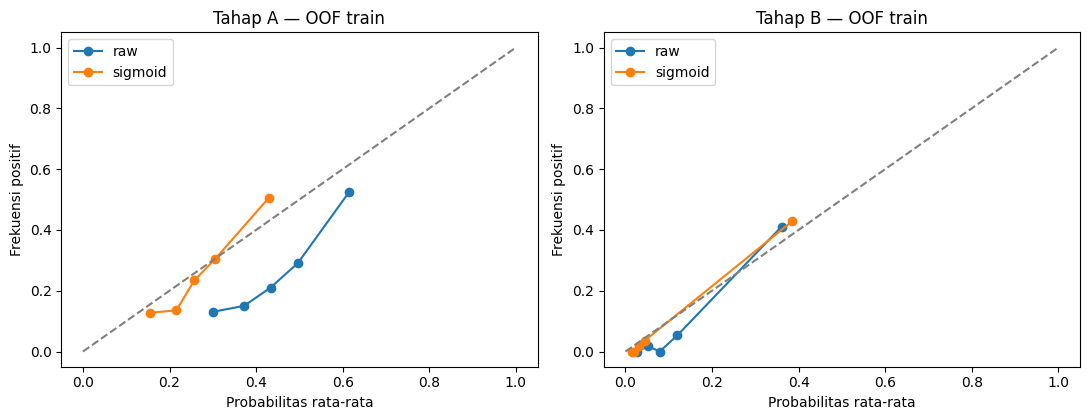

In [ ]:
def cv_probs(estimator,X,y,seed):
    cv=StratifiedKFold(n_splits=CV_FOLDS,shuffle=True,random_state=seed)
    return cross_val_predict(estimator,X,y,cv=cv,method='predict_proba',n_jobs=1)[:,1]

calibration_rows=[]
oof={}
for stage,Xs,ys in [('A',Xa,ya),('B',Xb,yb)]:
    for kind,est in [('raw',base_estimator(stage)),('sigmoid',calibrated_model(stage))]:
        p=cv_probs(est,Xs,ys,SEED+20)
        oof[(stage,kind)]=p
        calibration_rows.append({'tahap':stage,'metode':kind,'n':len(ys),'positif':int(ys.sum()),
            'brier':brier_score_loss(ys,p),'pr_auc':average_precision_score(ys,p),
            'roc_auc':roc_auc_score(ys,p),'log_loss':log_loss(ys,np.column_stack([1-p,p]),labels=[0,1])})
calib_report=pd.DataFrame(calibration_rows)
calib_report.to_csv(OUT_DIR/'05_kalibrasi_OOF_training.csv',index=False,encoding='utf-8-sig')
display(calib_report.round(5))
fig,axes=plt.subplots(1,2,figsize=(11,4.3))
for ax,stage,ys in zip(axes,['A','B'],[ya,yb]):
    for kind in ['raw','sigmoid']:
        obs,pred=calibration_curve(ys,oof[(stage,kind)],n_bins=5,strategy='quantile')
        ax.plot(pred,obs,marker='o',label=kind)
    ax.plot([0,1],[0,1],linestyle='--',color='gray');ax.set(xlabel='Probabilitas rata-rata',ylabel='Frekuensi positif',title=f'Tahap {stage} — OOF train')
    ax.legend()
fig.tight_layout();fig.savefig(OUT_DIR/'05_kurva_kalibrasi_OOF.png',dpi=180,bbox_inches='tight');plt.show()

## 7. Tentukan threshold A dan B hanya dari probabilitas OOF terkalibrasi pada training

**Perhatian:** threshold Tahap A lama = 0,44 (sebelum kalibrasi), sedangkan yang digunakan di DSS terintegrasi adalah nilai baru yang diseleksi dari prediksi **OOF terkalibrasi**, bukan dari holdout. Threshold dari OOF training merupakan nilai operasional, bukan bukti performa yang tidak bias.

In [ ]:
THRESH_GRID=np.round(np.linspace(0.05,0.95,91),2)
def threshold_search(y,p):
    rows=[]
    for t in THRESH_GRID:
        yp=(p>=t).astype(int)
        rows.append({'threshold':float(t),'f1':f1_score(y,yp,zero_division=0),
            'balanced_accuracy':balanced_accuracy_score(y,yp),
            'recall':recall_score(y,yp,zero_division=0),
            'precision':precision_score(y,yp,zero_division=0)})
    tb=pd.DataFrame(rows)
    tb['tie_break']=-abs(tb['threshold']-0.5)
    best=tb.sort_values(['f1','balanced_accuracy','recall','tie_break'],ascending=False).iloc[0]
    return float(best['threshold']),tb.drop(columns='tie_break')

THRESH_A,gridA=threshold_search(ya,oof[('A','sigmoid')])
THRESH_B,gridB=threshold_search(yb,oof[('B','sigmoid')])
gridA.to_csv(OUT_DIR/'06_threshold_grid_A_training_OOF.csv',index=False,encoding='utf-8-sig')
gridB.to_csv(OUT_DIR/'06_threshold_grid_B_training_OOF.csv',index=False,encoding='utf-8-sig')
print('A threshold lama uncalibrated:',REF_A_THRESHOLD_UNCALIBRATED,
      '| A baru calibrated OOF:',THRESH_A,'| B calibrated OOF:',THRESH_B)
print('TIADA threshold berasal dari test/holdout.')

A threshold lama uncalibrated: 0.44 | A baru calibrated OOF: 0.26 | B calibrated OOF: 0.31
TIADA threshold berasal dari test/holdout.


## 8. Nested CV dua-tahap untuk evaluasi gabungan 3-kelas pada TRAINING saja

Pada setiap *outer fold*, threshold dihitung ulang hanya dari OOF bagian *outer train*. Kemudian model terkalibrasi di-fit ulang menggunakan *outer train* dan diujikan pada *outer validation* yang belum terlihat. Tahap B hanya mempelajari Maju/Mandiri yang ada pada fold pelatihan. **Ini evaluasi internal yang lebih jujur daripada menggunakan threshold global hasil training OOF pada fold yang sama.**

In [ ]:
def hierarchy_probs(ma,mb,X):
    pa=ma.predict_proba(X)[:,1]
    pb=mb.predict_proba(X)[:,1]
    out=np.column_stack([1-pa,pa*(1-pb),pa*pb])
    assert np.allclose(out.sum(axis=1),1,atol=1e-9)
    return out,pa,pb

def hierarchy_labels(pa,pb,ta,tb):
    return np.where(pa<ta,0,np.where(pb<tb,1,2)).astype(int)

def binary_metrics(y,p,t):
    yp=(p>=t).astype(int)
    return {'pr_auc':average_precision_score(y,p),'roc_auc':roc_auc_score(y,p),
        'accuracy':accuracy_score(y,yp),'balanced_accuracy':balanced_accuracy_score(y,yp),
        'precision':precision_score(y,yp,zero_division=0),'recall':recall_score(y,yp,zero_division=0),
        'f1':f1_score(y,yp,zero_division=0),'brier':brier_score_loss(y,p)}

if RUN_NESTED_HIERARCHY:
    all_y=train['label_3kelas'].astype(int).to_numpy()
    nested=np.full((len(train),3),np.nan); nested_pred=np.full(len(train),-1,dtype=int)
    nested_thresholds=[]
    split=StratifiedKFold(n_splits=OUTER_FOLDS,shuffle=True,random_state=SEED+33)
    for fold,(itr,iva) in enumerate(split.split(Xa,all_y),start=1):
        Xi=Xa.iloc[itr].reset_index(drop=True); yi=all_y[itr]
        Xv=Xa.iloc[iva].reset_index(drop=True)
        yAi=(yi>=1).astype(int)
        idxB=np.where(yi>=1)[0]; XBi=Xi.iloc[idxB].reset_index(drop=True);yBi=(yi[idxB]==2).astype(int)
        pA_i=cv_probs(calibrated_model('A'),Xi,yAi,SEED+100+fold)
        pB_i=cv_probs(calibrated_model('B'),XBi,yBi,SEED+200+fold)
        tA_i,_=threshold_search(yAi,pA_i);tB_i,_=threshold_search(yBi,pB_i)
        mA_i=calibrated_model('A').fit(Xi,yAi)
        mB_i=calibrated_model('B').fit(XBi,yBi)
        prob,pa,pb=hierarchy_probs(mA_i,mB_i,Xv)
        nested[iva]=prob;nested_pred[iva]=hierarchy_labels(pa,pb,tA_i,tB_i)
        nested_thresholds.append({'outer_fold':fold,'threshold_A':tA_i,'threshold_B':tB_i,
            'n_outer_valid':len(iva),'mandiri_outer_valid':int((all_y[iva]==2).sum())})
        print('Nested fold',fold,'/',OUTER_FOLDS,'A=',tA_i,'B=',tB_i)
    assert np.isfinite(nested).all() and (nested_pred>=0).all()
    nested3={'accuracy':accuracy_score(all_y,nested_pred),
        'balanced_accuracy':balanced_accuracy_score(all_y,nested_pred),
        'macro_f1':f1_score(all_y,nested_pred,average='macro',zero_division=0),
        'mandiri_recall':recall_score(all_y,nested_pred,labels=[2],average='macro',zero_division=0),
        'mandiri_f1':f1_score(all_y,nested_pred,labels=[2],average='macro',zero_division=0),
        'macro_ovr_ap':np.mean([average_precision_score((all_y==k).astype(int),nested[:,k]) for k in [0,1,2]]),
        'n':len(all_y)}
    pd.DataFrame([nested3]).to_csv(OUT_DIR/'07_nested_3kelas_metrics_training.csv',index=False,encoding='utf-8-sig')
    pd.DataFrame(nested_thresholds).to_csv(OUT_DIR/'07_nested_3kelas_thresholds.csv',index=False,encoding='utf-8-sig')
    nested_df=train[['matching_key','Desa Wisata','Kabupaten','label_3kelas']].reset_index(drop=True).copy()
    nested_df['prediksi']=nested_pred
    for k in range(3):nested_df[f'prob_kelas_{k}']=nested[:,k]
    nested_df.to_csv(OUT_DIR/'07_nested_3kelas_prediksi_OOF_training.csv',index=False,encoding='utf-8-sig')
    print('NESTED INTERNAL TRAINING:');display(pd.DataFrame([nested3]).round(4))
else: print('Nested hierarchical CV tidak dijalankan. Jangan klaim evaluasi 3 kelas yang baru.')

Nested fold 1 / 3 A= 0.25 B= 0.21
Nested fold 2 / 3 A= 0.28 B= 0.37
Nested fold 3 / 3 A= 0.27 B= 0.23
NESTED INTERNAL TRAINING:


,accuracy,balanced_accuracy,macro_f1,mandiri_recall,mandiri_f1,macro_ovr_ap,n
0,0.6367,0.6682,0.6773,0.7778,0.875,0.7014,1068


## 9. Latih model A/B dengan training terkunci; diagnosa holdout lama hanya jika diizinkan

**Tidak ada pemilihan model atau threshold menggunakan holdout.** Jika diagnostik diaktifkan, nama file menandai bahwa data ini **telah diperiksa sebelumnya**; hindari pelaporan sebagai pengujian independen baru.

,tahap,n,pr_auc,roc_auc,accuracy,balanced_accuracy,precision,recall,f1,brier,peringatan
0,A,268,0.5346,0.7090,0.6455,0.6770,0.4031,0.7429,0.5226,0.1695,HOLDOUT LAMA TELAH DIPERIKSA; hasil hanya diag...
1,B,70,0.9405,0.9887,0.9857,0.9286,1.0000,0.8571,0.9231,0.0144,HOLDOUT LAMA TELAH DIPERIKSA; hasil hanya diag...


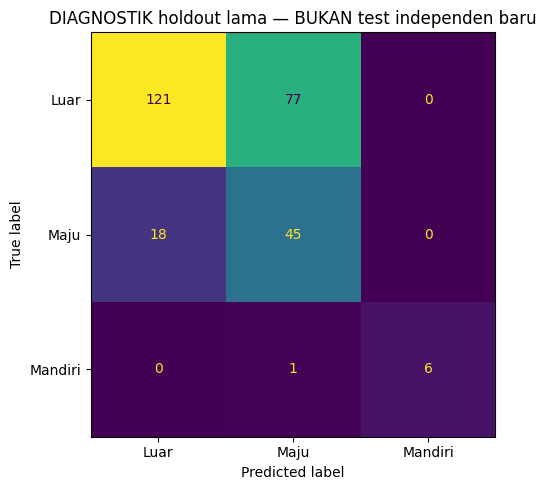

In [ ]:
model_A_train=calibrated_model('A').fit(Xa,ya)
model_B_train=calibrated_model('B').fit(Xb,yb)

if RUN_REUSED_HOLDOUT_DIAGNOSTIC:
    Xtest=test[XCOLS].reset_index(drop=True)
    yy=test['label_3kelas'].astype(int).to_numpy()
    P,pa,pb=hierarchy_probs(model_A_train,model_B_train,Xtest)
    yh=hierarchy_labels(pa,pb,THRESH_A,THRESH_B)
    ybtest=test.loc[test['label_3kelas'].isin([1,2]),'label_3kelas'].eq(2).astype(int).to_numpy()
    Xbtest=test.loc[test['label_3kelas'].isin([1,2]),XCOLS].reset_index(drop=True)
    Pb=model_B_train.predict_proba(Xbtest)[:,1]
    diagA=binary_metrics((yy>=1).astype(int),pa,THRESH_A)
    diagB=binary_metrics(ybtest,Pb,THRESH_B)
    diag=pd.DataFrame([{'tahap':'A','n':len(yy),**diagA}, {'tahap':'B','n':len(ybtest),**diagB}])
    diag['peringatan']='HOLDOUT LAMA TELAH DIPERIKSA; hasil hanya diagnostik, bukan independen baru'
    diag.to_csv(OUT_DIR/'08_DIAGNOSTIK_HOLDOUT_LAMA_tahap_AB.csv',index=False,encoding='utf-8-sig')
    display(diag.round(4))
    cm=confusion_matrix(yy,yh,labels=[0,1,2])
    pd.DataFrame(cm,index=['actual_0','actual_1','actual_2'],columns=['pred_0','pred_1','pred_2']).to_csv(
        OUT_DIR/'08_DIAGNOSTIK_HOLDOUT_LAMA_confusion.csv',encoding='utf-8-sig')
    fig,ax=plt.subplots(figsize=(6,5))
    ConfusionMatrixDisplay(cm,display_labels=['Luar','Maju','Mandiri']).plot(ax=ax,values_format='d',colorbar=False)
    ax.set_title('DIAGNOSTIK holdout lama — BUKAN test independen baru')
    fig.tight_layout();fig.savefig(OUT_DIR/'08_DIAGNOSTIK_HOLDOUT_LAMA_cm.png',dpi=180);plt.show()
    diag_pred=test[['matching_key','Desa Wisata','Kabupaten','label_3kelas']].reset_index(drop=True).copy()
    diag_pred['prediksi']=yh;diag_pred['p_tingkat_lanjut']=pa;diag_pred['p_mandiri_kondisional']=pb
    diag_pred['p_mandiri_gabungan']=P[:,2]
    diag_pred.to_csv(OUT_DIR/'08_DIAGNOSTIK_HOLDOUT_LAMA_prediksi.csv',index=False,encoding='utf-8-sig')

## 10. Refit pada seluruh data dan hasilkan skor DSS — bukan evaluasi generalisasi

Model *deployment* mengolah seluruh 1.336 profil, termasuk data yang sebelumnya berada pada test. Tabel skor adalah hasil **in-sample** dengan model deployment; tidak boleh dipakai menghitung akurasi baru. Dua dimensi skor disediakan: kemiripan dengan tingkat lanjut (A) dan kemiripan dengan Mandiri (A × B). **Band 0–20–40–60–80–100 hanya band heuristik eksploratif.** Prioritas di luar benchmark juga diberikan sebagai *percentile rank* di antara 987 desa.

In [ ]:
Xall=df[XCOLS].reset_index(drop=True)
model_A_deploy=calibrated_model('A').fit(Xall,(df['label_3kelas'].to_numpy()>=1).astype(int))
partB=df[df['label_3kelas'].isin([1,2])]
model_B_deploy=calibrated_model('B').fit(partB[XCOLS].reset_index(drop=True),(partB['label_3kelas'].to_numpy()==2).astype(int))
P_all,pa_all,pb_all=hierarchy_probs(model_A_deploy,model_B_deploy,Xall)
pred_all=hierarchy_labels(pa_all,pb_all,THRESH_A,THRESH_B)

score=df[['matching_key','Desa Wisata','Kabupaten','label_3kelas','status_benchmark','status_terverifikasi_JADESTA']+NUM_COLS].copy()
score['prediksi_label_model']=pred_all
score['score_tingkat_lanjut_0_100']=100*pa_all
score['score_mandiri_kondisional_0_100']=100*pb_all
score['score_menuju_mandiri_0_100']=100*P_all[:,2]
score['label_kategori_eksploratif']=pd.cut(score['score_menuju_mandiri_0_100'],
    bins=[-0.0001,20,40,60,80,100.0001],labels=['Low','Emerging','Moderate','High','Very High']).astype(str)
score['peringatan']='Skor benchmark-alignment in-sample; label belum diverifikasi JADESTA'
mask_out=score['label_3kelas']==0
score['percentile_prioritas_dalam_luar_benchmark']=np.nan
score.loc[mask_out,'percentile_prioritas_dalam_luar_benchmark']=score.loc[mask_out,'score_tingkat_lanjut_0_100'].rank(pct=True)*100
score.to_csv(OUT_DIR/'09_DSS_SCORES_1336.csv',index=False,encoding='utf-8-sig')
score[mask_out].sort_values('score_tingkat_lanjut_0_100',ascending=False).to_csv(
    OUT_DIR/'09_PRIORITAS_987_DI_LUAR_BENCHMARK.csv',index=False,encoding='utf-8-sig')
print('Top 10 kelas 0 berdasarkan skor tingkat lanjut (indikatif):')
display(score[mask_out].sort_values('score_tingkat_lanjut_0_100',ascending=False)[
    ['Desa Wisata','Kabupaten','score_tingkat_lanjut_0_100','score_menuju_mandiri_0_100','percentile_prioritas_dalam_luar_benchmark']].head(10).round(3))
print('Distribusi kategori HEURISTIK:')
display(score['label_kategori_eksploratif'].value_counts().to_frame('n'))

Top 10 kelas 0 berdasarkan skor tingkat lanjut (indikatif):


,Desa Wisata,Kabupaten,score_tingkat_lanjut_0_100,score_menuju_mandiri_0_100,percentile_prioritas_dalam_luar_benchmark
131,Desa Wisata Rts (rawang Tinjau Sitiung),Kabupaten Dharmasraya,68.228,1.717,100.000
40,Desa Wisata Ekang,Kabupaten Bintan,56.428,2.473,99.899
69,Desa Wisata Pejambon,Kabupaten Bojonegoro,53.255,1.503,99.797
953,Desa Wisata Kertarahayu,Kabupaten Bekasi,52.185,1.692,99.696
269,Desa Wisata Religi Bubohu,Kabupaten Gorontalo,51.386,1.345,99.595
883,Desa Wisata PASIR SUNUR,Kota Pariaman,51.220,1.614,99.493
186,Desa Wisata Dewi Mukti,Kabupaten Gresik,50.869,1.485,99.392
521,Desa Wisata Beleka Sentra Rotan & Ketak/atte,Kabupaten Lombok Tengah,48.141,2.117,99.291
966,Desa Wisata Ketindan TRAD,Kabupaten Malang,47.978,1.188,99.189
109,Desa Wisata Dewa Katar ( Karang Taruna,Kabupaten Tanah Laut,46.919,0.935,99.088


Distribusi kategori HEURISTIK:


,n
label_kategori_eksploratif,
Low,1302
High,17
Moderate,10
Emerging,7


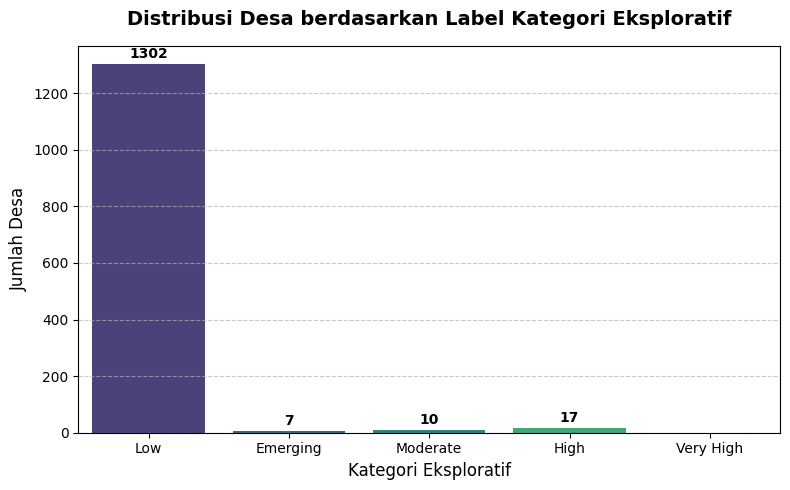

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Menghitung frekuensi tiap kategori
kat_counts = score['label_kategori_eksploratif'].value_counts().reindex(['Low', 'Emerging', 'Moderate', 'High', 'Very High'])

# Membuat visualisasi bar chart
plt.figure(figsize=(8, 5))
sns.barplot(x=kat_counts.index, y=kat_counts.values, palette='viridis', hue=kat_counts.index, legend=False)

plt.title('Distribusi Desa berdasarkan Label Kategori Eksploratif', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Kategori Eksploratif', fontsize=12)
plt.ylabel('Jumlah Desa', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Menambahkan label nilai di atas bar
for i, val in enumerate(kat_counts.values):
    if not pd.isna(val):
        plt.text(i, val + 10, str(int(val)), ha='center', va='bottom', fontsize=10, fontweight='bold')

# Menyimpan grafik ke direktori hasil
plt.tight_layout()
plt.savefig(OUT_DIR/'13_distribusi_kategori_eksploratif.png', dpi=180)
plt.show()

## 11. Rekomendasi DSS berdasarkan kesenjangan benchmark Maju / Mandiri

Untuk kelas 0, target pembanding = median kelompok Maju. Untuk Maju, target = median Mandiri. Indikator yang median targetnya nol atau lebih rendah tidak dipaksakan sebagai target peningkatan. Semua rekomendasi diperlakukan sebagai **usulan verifikasi kelengkapan dokumentasi dan kebutuhan pengembangan**, bukan keputusan otomatis membangun fasilitas.

In [ ]:
ACTIONS={
 'num_facilities':'Periksa kelengkapan dokumentasi dan mutu fasilitas dasar wisata; konfirmasi melalui observasi lapangan.',
 'num_attractions':'Inventarisasi dan lengkapi deskripsi atraksi, pengalaman wisata, dan kualitas layanan.',
 'num_homestay':'Audit keberadaan dan mutu homestay; jangan menganggap data kosong berarti tidak tersedia.',
 'num_tour_packages':'Dokumentasikan pilihan paket wisata, harga, durasi, dan layanan yang tersedia.',
 'num_souvenirs':'Periksa keberadaan produk UMKM/suvenir lokal dan lengkapi dokumentasinya.',
 'has_instagram':'Verifikasi akun resmi Instagram dan perbarui informasi destinasi bila diperlukan.',
 'has_facebook':'Periksa apakah Facebook relevan dengan sasaran promosi dan lengkapi kanalnya bila perlu.',
 'has_website':'Verifikasi situs destinasi dan kelengkapan informasi publik bila tersedia.'
}
med=df.groupby('label_3kelas')[list(ACTIONS)].median().T
med.columns=[LABEL_NAMES[int(c)] for c in med.columns]
med.to_csv(OUT_DIR/'10_benchmark_median.csv',encoding='utf-8-sig')
recs=[]
for ix,row in score.iterrows():
    cl=int(row['label_3kelas'])
    if cl==2:continue
    target=1 if cl==0 else 2
    pool=df[df['label_3kelas']==target]
    median=pool[list(ACTIONS)].median()
    candidates=[]
    for feat,action in ACTIONS.items():
        dest=float(median[feat]);cur=float(row[feat]);gap=max(dest-cur,0)
        if dest<=0 or gap==0:continue
        norm=gap/max(dest,1)
        candidates.append((norm,gap,feat,cur,dest,action))
    for rank,(norm,gap,feat,cur,dest,action) in enumerate(sorted(candidates,reverse=True)[:3],1):
        recs.append({'matching_key':row['matching_key'],'Desa Wisata':row['Desa Wisata'],
            'Kabupaten':row['Kabupaten'],'kelas_referensi':LABEL_NAMES[cl],
            'benchmark_tujuan':LABEL_NAMES[target],'prioritas':rank,'fitur':feat,
            'nilai_tercatat':cur,'median_benchmark':dest,'gap':gap,'gap_normalized':norm,
            'rekomendasi_indikatif':action,
            'keterbatasan':'Data dokumentasi; keputusan butuh verifikasi desa/pakar; status resmi belum diverifikasi'})
rec_df=pd.DataFrame(recs)
rec_df.to_csv(OUT_DIR/'10_rekomendasi_top3_indikatif.csv',index=False,encoding='utf-8-sig')
print('Total rekomendasi',len(rec_df));display(med);display(rec_df.head(8))

Total rekomendasi 3100


,Di Luar Benchmark,Maju,Mandiri
num_facilities,7.0,10.0,10.0
num_attractions,2.0,5.0,4.0
num_homestay,0.0,2.0,0.0
num_tour_packages,1.0,2.0,1.0
num_souvenirs,0.0,2.0,0.5
has_instagram,1.0,1.0,1.0
has_facebook,1.0,1.0,1.0
has_website,0.0,1.0,1.0


,matching_key,Desa Wisata,Kabupaten,kelas_referensi,benchmark_tujuan,prioritas,fitur,nilai_tercatat,median_benchmark,gap,gap_normalized,rekomendasi_indikatif,keterbatasan
0,pagak | banjarnegara,Desa Wisata Pagak,Kabupaten Banjarnegara,Di Luar Benchmark,Maju,1,num_souvenirs,0.0,2.0,2.0,1.0,Periksa keberadaan produk UMKM/suvenir lokal d...,Data dokumentasi; keputusan butuh verifikasi d...
1,pagak | banjarnegara,Desa Wisata Pagak,Kabupaten Banjarnegara,Di Luar Benchmark,Maju,2,num_homestay,0.0,2.0,2.0,1.0,Audit keberadaan dan mutu homestay; jangan men...,Data dokumentasi; keputusan butuh verifikasi d...
2,pagak | banjarnegara,Desa Wisata Pagak,Kabupaten Banjarnegara,Di Luar Benchmark,Maju,3,num_attractions,1.0,5.0,4.0,0.8,"Inventarisasi dan lengkapi deskripsi atraksi, ...",Data dokumentasi; keputusan butuh verifikasi d...
3,makmur jaya | bangli,Desa Wisata Makmur Jaya,Kabupaten Bangli,Di Luar Benchmark,Maju,1,num_facilities,0.0,10.0,10.0,1.0,Periksa kelengkapan dokumentasi dan mutu fasil...,Data dokumentasi; keputusan butuh verifikasi d...
4,makmur jaya | bangli,Desa Wisata Makmur Jaya,Kabupaten Bangli,Di Luar Benchmark,Maju,2,num_attractions,0.0,5.0,5.0,1.0,"Inventarisasi dan lengkapi deskripsi atraksi, ...",Data dokumentasi; keputusan butuh verifikasi d...
5,makmur jaya | bangli,Desa Wisata Makmur Jaya,Kabupaten Bangli,Di Luar Benchmark,Maju,3,num_tour_packages,0.0,2.0,2.0,1.0,"Dokumentasikan pilihan paket wisata, harga, du...",Data dokumentasi; keputusan butuh verifikasi d...
6,panundaan | bandung,Desa Wisata Panundaan,Kabupaten Bandung,Di Luar Benchmark,Maju,1,num_attractions,0.0,5.0,5.0,1.0,"Inventarisasi dan lengkapi deskripsi atraksi, ...",Data dokumentasi; keputusan butuh verifikasi d...
7,panundaan | bandung,Desa Wisata Panundaan,Kabupaten Bandung,Di Luar Benchmark,Maju,2,num_tour_packages,0.0,2.0,2.0,1.0,"Dokumentasikan pilihan paket wisata, harga, du...",Data dokumentasi; keputusan butuh verifikasi d...


## 12. Model-agnostic Permutation SHAP — jelaskan **fungsi skor akhir A × B** tanpa XGBoost

12 fitur numerik dipermutasi secara individual, sedangkan semua teks TF-IDF diperlakukan sebagai **satu kelompok input**. SHAP dihitung pada model deployment yang sama dengan `09_DSS_SCORES_1336.csv`, bukan pada model surrogate. Output SHAP berada dalam unit **probabilitas** (0–1). Karena permutasi independen dapat menciptakan kombinasi fitur yang tidak lazim, interpretasi tetap bersifat asosiasi prediktif dan nonkausal.

PermutationExplainer explainer: 19it [00:48,  3.26s/it]


SHAP lulus konsistensi skor dan aditivitas. Max error: 2.220446049250313e-16


,fitur,mean_abs_SHAP_weighted,mean_abs_SHAP_sample
12,TF-IDF (seluruh teks),0.10153,0.16528
0,description_length,0.00067,0.00103
10,has_website,0.00054,0.00064
8,has_facebook,0.00031,0.00046
3,num_homestay,0.00022,0.00026
1,num_facilities,0.00019,0.00030
4,num_tour_packages,0.00018,0.00028
5,num_souvenirs,0.00016,0.00019
2,num_attractions,0.00014,0.00019
11,has_twitter,0.00004,0.00007


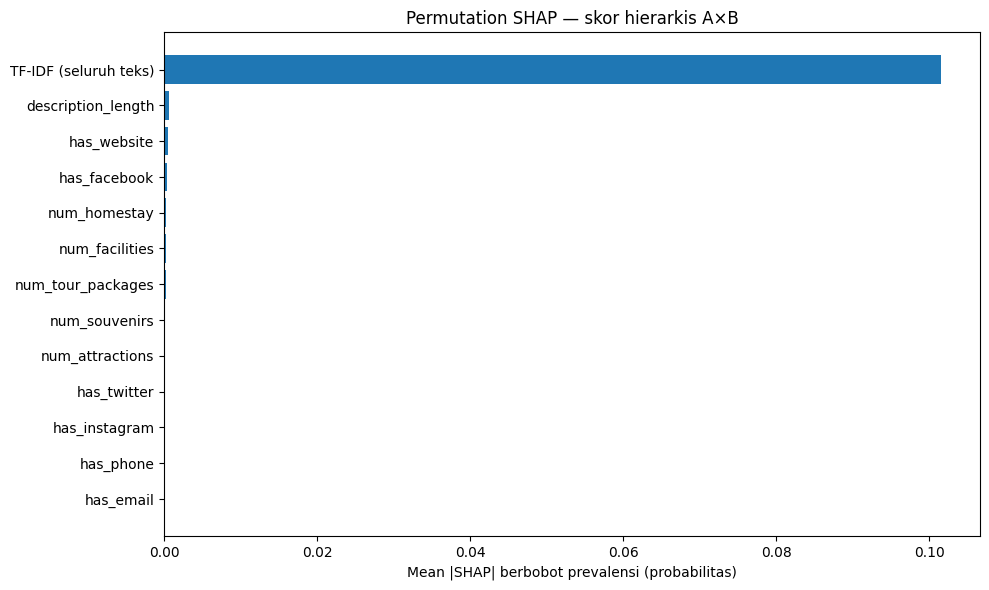

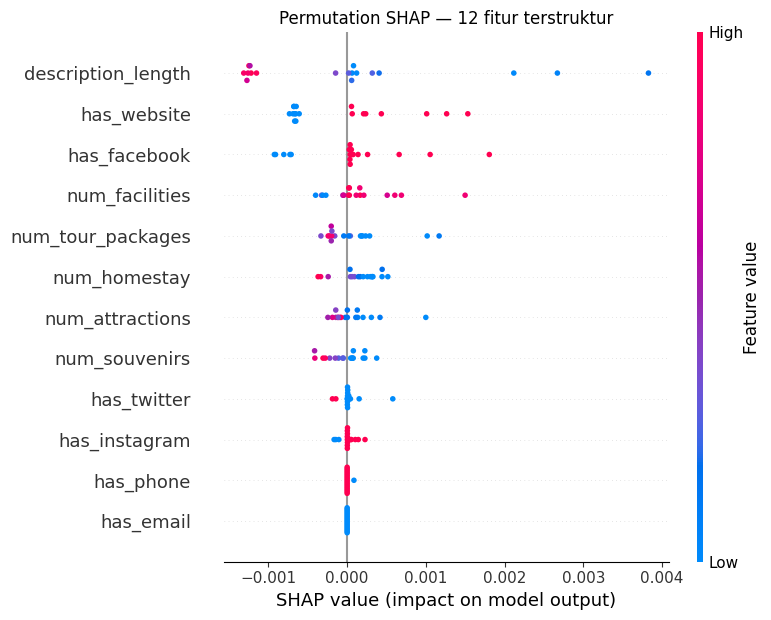

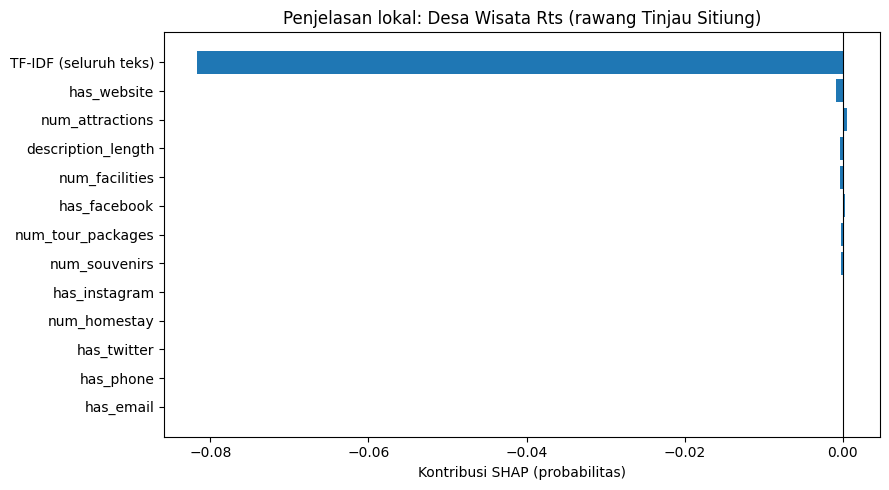

In [ ]:
if RUN_SHAP:
    try:
        import shap
    except ImportError:
        import subprocess
        subprocess.check_call([sys.executable,'-m','pip','-q','install','shap>=0.46,<1'])
        import shap

    text_bank=pd.Index(Xall[TEXT_COL].fillna('').astype(str).unique())
    id_text={text:i for i,text in enumerate(text_bank)}
    Xnum=Xall[XCOLS].copy()
    Xnum[TEXT_COL]=Xnum[TEXT_COL].map(id_text).astype(float)
    Xnum=Xnum.astype(float)

    def shap_score_model(Z):
        zz=np.atleast_2d(np.asarray(Z,dtype=float))
        raw=pd.DataFrame(zz,columns=XCOLS)
        ids=np.rint(raw[TEXT_COL].to_numpy()).astype(int)
        if (ids<0).any() or (ids>=len(text_bank)).any():
            raise ValueError('Text ID tidak valid. Masker harus memilih ID asli, bukan interpolasi.')
        raw[TEXT_COL]=text_bank.take(ids).astype(str)
        probs,_,_=hierarchy_probs(model_A_deploy,model_B_deploy,raw[XCOLS])
        return probs[:,2]

    assert np.allclose(shap_score_model(Xnum.iloc[:12].to_numpy()),P_all[:12,2],atol=1e-8), (
        'Wrapper SHAP tidak sesuai skor yang dikeluarkan DSS!')
    def choose_strata(counts,seed):
        idx=[]
        for k,n in enumerate(counts):
            sub=df.index[df['label_3kelas']==k]
            take=min(int(n),len(sub))
            idx+=sub.to_series().sample(n=take,random_state=seed+k).tolist()
        return np.asarray(idx,dtype=int)
    idx_bg=choose_strata(BG_COUNTS,SEED+450)
    idx_exp=choose_strata(EXP_COUNTS,SEED+500)
    zbg=Xnum.iloc[idx_bg].copy();zexp=Xnum.iloc[idx_exp].copy()
    D=len(XCOLS);MAX_EVALS=SHAP_PERMUTATIONS*(2*D+1)
    exp=shap.Explainer(shap_score_model,shap.maskers.Independent(zbg,max_samples=len(zbg)),
        algorithm='permutation',feature_names=NUM_COLS+['TF-IDF (seluruh teks)'],seed=SEED)
    sv=exp(zexp,max_evals=MAX_EVALS)
    rawp=shap_score_model(zexp.to_numpy())
    deviation=np.max(np.abs(sv.base_values+sv.values.sum(axis=1)-rawp))
    assert deviation<1e-5, f'Aditivitas SHAP tidak terpenuhi: {deviation}'
    print('SHAP lulus konsistensi skor dan aditivitas. Max error:',deviation)
    cl_exp=df.loc[idx_exp,'label_3kelas'].to_numpy()
    priors=df['label_3kelas'].value_counts(normalize=True).to_dict()
    imp=np.zeros(D)
    for k,prior in priors.items():
        imp+=prior*np.abs(sv.values[cl_exp==k]).mean(axis=0)
    imp_df=pd.DataFrame({'fitur':NUM_COLS+['TF-IDF (seluruh teks)'],
        'mean_abs_SHAP_weighted':imp,'mean_abs_SHAP_sample':np.abs(sv.values).mean(axis=0)})
    imp_df=imp_df.sort_values('mean_abs_SHAP_weighted',ascending=False)
    imp_df.to_csv(OUT_DIR/'11_SHAP_global_importance.csv',index=False,encoding='utf-8-sig')
    display(imp_df.round(5))
    fig,ax=plt.subplots(figsize=(10,6));ax.barh(imp_df['fitur'].iloc[::-1],imp_df['mean_abs_SHAP_weighted'].iloc[::-1])
    ax.set(xlabel='Mean |SHAP| berbobot prevalensi (probabilitas)',title='Permutation SHAP — skor hierarkis A×B')
    fig.tight_layout();fig.savefig(OUT_DIR/'11_SHAP_global.png',dpi=190,bbox_inches='tight');plt.show()
    shap.plots.beeswarm(sv[:,:len(NUM_COLS)],max_display=len(NUM_COLS),show=False)
    plt.title('Permutation SHAP — 12 fitur terstruktur')
    plt.tight_layout();plt.savefig(OUT_DIR/'11_SHAP_beeswarm_numerik.png',dpi=190,bbox_inches='tight');plt.show()
    outside=score[score['label_3kelas']==0].sort_values('score_tingkat_lanjut_0_100',ascending=False)
    idx_local=int(outside.index[0]);local=exp(Xnum.loc[[idx_local]],max_evals=MAX_EVALS)
    local_df=pd.DataFrame({'fitur':NUM_COLS+['TF-IDF (seluruh teks)'],
       'shap_p_mandiri':local.values[0]})
    local_df['abs']=local_df['shap_p_mandiri'].abs()
    local_df=local_df.sort_values('abs',ascending=False)
    local_df.to_csv(OUT_DIR/'11_SHAP_lokal_contoh.csv',index=False,encoding='utf-8-sig')
    fig,ax=plt.subplots(figsize=(9,5));ax.barh(local_df['fitur'].iloc[::-1],local_df['shap_p_mandiri'].iloc[::-1])
    ax.axvline(0,color='black',linewidth=0.8);ax.set_xlabel('Kontribusi SHAP (probabilitas)')
    ax.set_title('Penjelasan lokal: '+str(score.loc[idx_local,'Desa Wisata'])[:48])
    fig.tight_layout();fig.savefig(OUT_DIR/'11_SHAP_lokal.png',dpi=190,bbox_inches='tight');plt.show()
else:
    print('RUN_SHAP=False: analisis SHAP tidak dihitung. Untuk laporan artikel, jalankan kembali RUN_SHAP=True.')

In [ ]:
import pandas as pd

def cari_rekomendasi_desa(nama_desa):
    # Mencari data desa pada dataframe score
    hasil_skor = score[score['Desa Wisata'].str.contains(nama_desa, case=False, na=False)]

    if hasil_skor.empty:
        print(f"Desa dengan nama '{nama_desa}' tidak ditemukan.")
        return

    for idx, row in hasil_skor.iterrows():
        key = row['matching_key']
        print("="*60)
        print(f"DESA WISATA: {row['Desa Wisata']} ({row['Kabupaten']})")
        print(f"Status Benchmark Saat Ini: {row['status_benchmark']}")
        print(f"Prediksi Label Model: {LABEL_NAMES[row['prediksi_label_model']]}")
        print(f"Skor Menuju Mandiri (0-100): {row['score_menuju_mandiri_0_100']:.2f}")
        print(f"Label Kategori Eksploratif: {row['label_kategori_eksploratif']}")
        print("-"*60)

        # Mencari rekomendasi kesenjangan benchmark
        rekomendasi_desa = rec_df[rec_df['matching_key'] == key]
        if rekomendasi_desa.empty:
            print("Tidak ada rekomendasi kesenjangan benchmark (Desa kemungkinan sudah berada di tingkat Mandiri).")
        else:
            print("REKOMENDASI DSS BERDASARKAN KESENJANGAN BENCHMARK:")
            for _, rec in rekomendasi_desa.sort_values('prioritas').iterrows():
                print(f"{rec['prioritas']}. Fitur: {rec['fitur']}")
                print(f"   - Nilai Tercatat: {rec['nilai_tercatat']}")
                print(f"   - Median Target ({rec['benchmark_tujuan']}): {rec['median_benchmark']}")
                print(f"   - Gap Kesenjangan: {rec['gap']}")
                print(f"   - Tindakan Rekomendasi: {rec['rekomendasi_indikatif']}")
        print("="*60 + "\n")

# Silakan masukkan nama desa yang ingin dicari di bawah ini:
input_nama_desa = "brumbun"  # @param {type:"string"}
cari_rekomendasi_desa(input_nama_desa)

DESA WISATA: Desa Wisata BRUMBUN (Kabupaten Madiun)
Status Benchmark Saat Ini: Maju
Prediksi Label Model: Maju
Skor Menuju Mandiri (0-100): 1.09
Label Kategori Eksploratif: Low
------------------------------------------------------------
REKOMENDASI DSS BERDASARKAN KESENJANGAN BENCHMARK:
1. Fitur: has_website
   - Nilai Tercatat: 0.0
   - Median Target (Mandiri): 1.0
   - Gap Kesenjangan: 1.0
   - Tindakan Rekomendasi: Verifikasi situs destinasi dan kelengkapan informasi publik bila tersedia.
2. Fitur: num_souvenirs
   - Nilai Tercatat: 0.0
   - Median Target (Mandiri): 0.5
   - Gap Kesenjangan: 0.5
   - Tindakan Rekomendasi: Periksa keberadaan produk UMKM/suvenir lokal dan lengkapi dokumentasinya.



## 13. Ekspor model, manifest provenance, dan ZIP seluruh hasil

In [ ]:
if SAVE_MODELS:
    joblib.dump(model_A_train,OUT_DIR/'12_model_A_train_calibrated.joblib',compress=3)
    joblib.dump(model_B_train,OUT_DIR/'12_model_B_train_calibrated.joblib',compress=3)
    joblib.dump(model_A_deploy,OUT_DIR/'12_model_A_deploy_calibrated.joblib',compress=3)
    joblib.dump(model_B_deploy,OUT_DIR/'12_model_B_deploy_calibrated.joblib',compress=3)

manifest={
 'pipeline':'DSS benchmark hierarki A x B terkalibrasi + Permutation SHAP',
 'data_n':len(df),'distribusi':df['label_3kelas'].value_counts().sort_index().to_dict(),
 'labels_ja_desta':'SELURUHNYA BELUM TERVERIFIKASI',
 'label_0':'Tidak tercantum pada file benchmark, BUKAN status resmi Rintisan/Berkembang',
 'model_A':'Logistic Regression (balanced) + TF-IDF only',
 'model_B':'Random Forest (balanced_subsample) + 12 structured + TF-IDF',
 'reference_A_threshold_uncalibrated':REF_A_THRESHOLD_UNCALIBRATED,
 'reference_robustness_zip_observed':'FAST_MODE=true, outer3x1, inner2 (pilot); bukan full nested',
 'calibration':CAL_METHOD,'cv_inner':CV_FOLDS,
 'threshold_A_calibrated_train_oof':THRESH_A,'threshold_B_calibrated_train_oof':THRESH_B,
 'threshold_source':'OOF calibrated on locked TRAIN, never reused HOLDOUT',
 'nested_hierarchical_internal_enabled':RUN_NESTED_HIERARCHY,
 'holdout_diagnostic':'Already seen in earlier experiments; not independently evaluative',
 'deployed_model':'refit/calibrated on all 1336 data for in-sample DSS scores',
 'score':'pA(Maju+Mandiri proxy) * pB(Mandiri | advanced proxy), in [0,1]',
 'score_interpretation':'benchmark membership similarity, not official readiness probability',
 'readiness_bands':'heuristic 0/20/40/60/80/100; NOT empirically validated',
 'shap':{'applied':RUN_SHAP,'explainer':'PermutationExplainer on deployed A×B score',
        'units':'12 numeric + 1 whole-text group','background_counts':BG_COUNTS,
        'explained_counts':EXP_COUNTS,'permutations':SHAP_PERMUTATIONS},
 'split_sha_train':actual_train_sha,'split_sha_test':actual_test_sha,
 'fast_mode':FAST_MODE,'seed':SEED,
 'versions':{'python':platform.python_version(),'scikit_learn':SKLEARN_VERSION,'pandas':pd.__version__,'numpy':np.__version__}
}
if RUN_SHAP:manifest['versions']['shap']=shap.__version__
with open(OUT_DIR/'00_MANIFEST_REPRODUCIBILITY.json','w',encoding='utf-8') as f:json.dump(manifest,f,indent=2,ensure_ascii=False)
with open(OUT_DIR/'00_BACA_DULU.txt','w',encoding='utf-8') as f:
    f.write('DSS DESA WISATA FINAL — BATASAN AKADEMIK\n'
      'Label JADESTA belum diverifikasi; kelas 0 = di luar benchmark saja.\n'
      'Model A: LR+TFIDF; Model B: RF+numeric+TFIDF; kedua probabilitas dikalibrasi sigmoid dari TRAIN saja.\n'
      'Threshold diperoleh dari OOF TRAIN; holdout lama telah ditinjau pada eksperimen terdahulu.\n'
      'Skor semua desa berasal dari fit deployment pada semua data: in-sample, bukan validasi eksternal.\n'
      'Permutasi SHAP menjelaskan skor yang sama; kontribusi tidak kausal.\n'
      'Laporan artikel belum dapat disebut final sampai verifikasi label dan validasi independen.\n')
zip_path=OUT_DIR.parent/'HASIL_DSS_FINAL_AB_PERMUTATION_SHAP.zip'
with zipfile.ZipFile(zip_path,'w',zipfile.ZIP_DEFLATED) as z:
    for p in sorted(OUT_DIR.iterdir()):
        if p.is_file():z.write(p,p.name)
print('Output:',OUT_DIR, 'jumlah file',len(list(OUT_DIR.iterdir())))
print('ZIP:',zip_path)
try:
    from google.colab import files as colab_files
    colab_files.download(str(zip_path))
except ImportError:pass

Output: /content/HASIL_DSS_FINAL_AB jumlah file 32
ZIP: /content/HASIL_DSS_FINAL_AB_PERMUTATION_SHAP.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>